## Music Genre Classification using Transformer

This notebook implements an MFCC-based Transformer neural network for music genre classification on the GTZAN dataset.

The preprocessing pipeline, 3-second audio segmentation, 40-MFCC feature extraction, song-level data splitting (70% train / 15% validation / 15% test), and feature scaling are kept strictly consistent with the other project architectures (MLP, 1D CNN, and Transformer) to ensure a fair comparative benchmark.

1. Imports

Imports the libraries required for data processing, audio feature extraction, Transformer development, visualization, and evaluation.

In [15]:
import os
import re
import numpy as np
import pandas as pd
import librosa
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import EarlyStopping

print('TensorFlow Version:', tf.__version__)
print('Librosa Version:', librosa.__version__)

TensorFlow Version: 2.21.0
Librosa Version: 0.11.0


2. Configuration

Defines reproducibility settings, audio preprocessing parameters, training hyperparameters, and the results directory.

In [ ]:
# Reproducibility
RANDOM_SEED = 42
np.random.seed(RANDOM_SEED)
tf.random.set_seed(RANDOM_SEED)
tf.keras.utils.set_random_seed(RANDOM_SEED)

# Audio Preprocessing Parameters
SAMPLE_RATE = 22050
DURATION_PER_SEGMENT = 3  # seconds
N_MFCC = 40
N_FFT = 2048
HOP_LENGTH = 512

# Training Parameters
BATCH_SIZE = 32
MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 5
LEARNING_RATE = 0.001

# Results output directory
RESULTS_DIR = 'results'
os.makedirs(RESULTS_DIR, exist_ok=True)
print('Configuration configured successfully.')

Configuration configured successfully.


3. Dataset Download

Downloads the GTZAN dataset using KaggleHub and locates the dataset files.

In [ ]:
!pip install -q kagglehub

In [ ]:
import kagglehub
import os

dataset_path = kagglehub.dataset_download(
    "andradaolteanu/gtzan-dataset-music-genre-classification"
)

print("Dataset downloaded to:", dataset_path)

for root, dirs, files in os.walk(dataset_path):
    if "features_3_sec.csv" in files:
        print("CSV found:", os.path.join(root, "features_3_sec.csv"))
        print("Audio folders:", dirs)

100%|██████████| 1.21G/1.21G [00:11<00:00, 114MB/s]

Extracting files...


Dataset downloaded to: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1
CSV found: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data/features_3_sec.csv
Audio folders: ['images_original', 'genres_original']


4. Dataset Loading

Loads the dataset metadata and identifies the original songs associated with each audio segment.

In [ ]:
# Locate dataset path
csv_path = None
audio_base = None

possible_data_roots = [
    '/kaggle/input/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/Data',
    os.path.expanduser('~/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data'),
    '../Data',
    'Data'
]

for root in possible_data_roots:
    if os.path.exists(root):
        csv_path = os.path.join(root, 'features_3_sec.csv')
        audio_base = os.path.join(root, 'genres_original')
        break

if csv_path is None or not os.path.exists(csv_path):
    for root_dir, _, files in os.walk(os.path.expanduser('~/.cache/kagglehub')):
        if 'features_3_sec.csv' in files:
            csv_path = os.path.join(root_dir, 'features_3_sec.csv')
            audio_base = os.path.join(root_dir, 'genres_original')
            break

print('CSV Path:', csv_path)
print('Audio Base Directory:', audio_base)

df = pd.read_csv(csv_path)

# Extract unique original song ID (e.g., 'blues.00000.0.wav' -> 'blues.00000')
df['song_id'] = df['filename'].str.replace(r'\.\d+\.wav$', '', regex=True)

print(f'Total 3-sec segment entries: {len(df)}')
print(f'Unique original songs: {df["song_id"].nunique()}')
df[['filename', 'song_id', 'label']].head()

CSV Path: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data/features_3_sec.csv
Audio Base Directory: /root/.cache/kagglehub/datasets/andradaolteanu/gtzan-dataset-music-genre-classification/versions/1/Data/genres_original
Total 3-sec segment entries: 9990
Unique original songs: 1000


,filename,song_id,label
0,blues.00000.0.wav,blues.00000,blues
1,blues.00000.1.wav,blues.00000,blues
2,blues.00000.2.wav,blues.00000,blues
3,blues.00000.3.wav,blues.00000,blues
4,blues.00000.4.wav,blues.00000,blues


5. Audio Segmentation and MFCC Extraction

Divides audio into three-second segments and extracts 40 MFCC features for each time frame.

In [ ]:
X_mfcc = []
y_mfcc = []
song_ids_mfcc = []
skipped_files = []

for i, (song_id, group) in enumerate(df.groupby('song_id')):
    label = group['label'].iloc[0]
    audio_file = os.path.join(audio_base, label, song_id + '.wav')

    try:
        for _, row in group.iterrows():
            segment_no = int(re.search(r'\.(\d+)\.wav$', row['filename']).group(1))

            # Load only the 3-second segment slice
            audio, sr = librosa.load(
                audio_file,
                sr=SAMPLE_RATE,
                offset=segment_no * DURATION_PER_SEGMENT,
                duration=DURATION_PER_SEGMENT
            )

            if len(audio) < DURATION_PER_SEGMENT * SAMPLE_RATE * 0.9:
                continue

            mfcc = librosa.feature.mfcc(
                y=audio,
                sr=SAMPLE_RATE,
                n_mfcc=N_MFCC,
                n_fft=N_FFT,
                hop_length=HOP_LENGTH
            )

            # mfcc shape is (40, 130) -> transpose to (130, 40) for sequence modeling
            X_mfcc.append(mfcc.T)
            y_mfcc.append(label)
            song_ids_mfcc.append(song_id)

    except Exception as e:
        skipped_files.append(song_id)
        print(f'Skipped corrupted file: {song_id}')

    if (i + 1) % 200 == 0:
        print(f'Processed {i + 1}/1000 songs | Extracted segments: {len(X_mfcc)}')

X_mfcc = np.array(X_mfcc, dtype=np.float32)
y_mfcc = np.array(y_mfcc)
song_ids_mfcc = np.array(song_ids_mfcc)

print('\n========== EXTRACTION SUMMARY ==========')
print(f'MFCC Sequence Dataset Shape: {X_mfcc.shape}')
print(f'Labels Shape: {y_mfcc.shape}')
print(f'Unique Songs Processed: {len(np.unique(song_ids_mfcc))}')
print(f'Corrupted Songs Skipped: {len(skipped_files)} {skipped_files}')

Processed 200/1000 songs | Extracted segments: 1998
Processed 400/1000 songs | Extracted segments: 3994


/tmp/ipykernel_3439/1325894620.py:15: UserWarning: PySoundFile failed. Trying audioread instead.
  audio, sr = librosa.load(
/usr/local/lib/python3.13/dist-packages/librosa/core/audio.py:184: FutureWarning: librosa.core.audio.__audioread_load
	Deprecated as of librosa version 0.10.0.
	It will be removed in librosa version 1.0.
  y, sr_native = __audioread_load(path, offset, duration, dtype)


Skipped corrupted file: jazz.00054
Processed 600/1000 songs | Extracted segments: 5982
Processed 800/1000 songs | Extracted segments: 7982
Processed 1000/1000 songs | Extracted segments: 9980

========== EXTRACTION SUMMARY ==========
MFCC Sequence Dataset Shape: (9980, 130, 40)
Labels Shape: (9980,)
Unique Songs Processed: 999
Corrupted Songs Skipped: 1 ['jazz.00054']


6. Train / Validation / Test Split

Splits songs into training, validation, and test sets in a 70:15:15 ratio while maintaining genre representation.

In [ ]:
songs = df[['song_id', 'label']].drop_duplicates()

# 70% Train, 30% Temporary
train_songs, temp_songs = train_test_split(
    songs,
    test_size=0.30,
    random_state=RANDOM_SEED,
    stratify=songs['label']
)

# Split remaining 30% into 15% Validation and 15% Test
val_songs, test_songs = train_test_split(
    temp_songs,
    test_size=0.50,
    random_state=RANDOM_SEED,
    stratify=temp_songs['label']
)

train_ids = set(train_songs['song_id'])
val_ids = set(val_songs['song_id'])
test_ids = set(test_songs['song_id'])

# Segment masks based on song IDs
train_mask = np.array([s in train_ids for s in song_ids_mfcc])
val_mask = np.array([s in val_ids for s in song_ids_mfcc])
test_mask = np.array([s in test_ids for s in song_ids_mfcc])

X_train_raw = X_mfcc[train_mask]
X_val_raw = X_mfcc[val_mask]
X_test_raw = X_mfcc[test_mask]

y_train_raw = y_mfcc[train_mask]
y_val_raw = y_mfcc[val_mask]
y_test_raw = y_mfcc[test_mask]

print(f'Training Songs: {len(train_songs)} | Training Segments: {len(X_train_raw)}')
print(f'Validation Songs: {len(val_songs)} | Validation Segments: {len(X_val_raw)}')
print(f'Testing Songs: {len(test_songs)} | Testing Segments: {len(X_test_raw)}')

Training Songs: 700 | Training Segments: 6980
Validation Songs: 150 | Validation Segments: 1500
Testing Songs: 150 | Testing Segments: 1500


7. Feature Scaling

Standardizes MFCC features using statistics calculated exclusively from the training data.

In [ ]:
n_train, time_steps, n_features = X_train_raw.shape

scaler = StandardScaler()

# Reshape to 2D for feature-wise scaling across the 40 MFCCs
X_train_2d = scaler.fit_transform(X_train_raw.reshape(-1, n_features))
X_val_2d = scaler.transform(X_val_raw.reshape(-1, n_features))
X_test_2d = scaler.transform(X_test_raw.reshape(-1, n_features))

# Reshape back to 3D temporal sequence (samples, 130, 40)
X_train = X_train_2d.reshape(X_train_raw.shape)
X_val = X_val_2d.reshape(X_val_raw.shape)
X_test = X_test_2d.reshape(X_test_raw.shape)

print('X_train shape:', X_train.shape)
print('X_val shape:  ', X_val.shape)
print('X_test shape: ', X_test.shape)

X_train shape: (6980, 130, 40)
X_val shape:   (1500, 130, 40)
X_test shape:  (1500, 130, 40)


8. Label Encoding

Converts genre names into numerical labels for model training and evaluation.

In [ ]:
label_encoder = LabelEncoder()

y_train = label_encoder.fit_transform(y_train_raw)
y_val = label_encoder.transform(y_val_raw)
y_test = label_encoder.transform(y_test_raw)

print('Classes:', label_encoder.classes_)
print('Encoded label distribution (Test set):\n', pd.Series(y_test).value_counts().sort_index().to_dict())

Classes: ['blues' 'classical' 'country' 'disco' 'hiphop' 'jazz' 'metal' 'pop'
 'reggae' 'rock']
Encoded label distribution (Test set):
 {0: 150, 1: 150, 2: 150, 3: 150, 4: 150, 5: 150, 6: 150, 7: 150, 8: 150, 9: 150}


9. Transformer Model

Builds a Transformer encoder with positional embeddings, multi-head self-attention, and dense layers for genre classification.

In [ ]:

# 9. Transformer Model

from tensorflow.keras.layers import (
    Layer, Embedding, MultiHeadAttention, LayerNormalization,
    Add, GlobalAveragePooling1D, Dense, Dropout
)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam

# Positional embeddings help the model retain frame order
class PositionalEmbedding(Layer):
    def __init__(self, sequence_length, d_model, **kwargs):
        super().__init__(**kwargs)
        self.position_embedding = Embedding(
            input_dim=sequence_length,
            output_dim=d_model
        )

    def call(self, inputs):
        positions = tf.range(start=0, limit=tf.shape(inputs)[1], delta=1)
        return inputs + self.position_embedding(positions)


def transformer_encoder(inputs, d_model=128, num_heads=4,
                        ff_dim=256, dropout_rate=0.2):
    # Multi-head self-attention
    attention_output = MultiHeadAttention(
        num_heads=num_heads,
        key_dim=d_model // num_heads,
        dropout=dropout_rate
    )(inputs, inputs)

    attention_output = Dropout(dropout_rate)(attention_output)
    x = Add()([inputs, attention_output])
    x = LayerNormalization(epsilon=1e-6)(x)

    # Feed-forward network
    ff_output = Dense(ff_dim, activation="relu")(x)
    ff_output = Dropout(dropout_rate)(ff_output)
    ff_output = Dense(d_model)(ff_output)

    x = Add()([x, ff_output])
    x = LayerNormalization(epsilon=1e-6)(x)
    return x


def build_transformer_model(
    sequence_length=130,
    n_features=40,
    num_classes=10,
    d_model=128,
    num_heads=4,
    ff_dim=256,
    num_blocks=2,
    dropout_rate=0.2
):
    inputs = Input(shape=(sequence_length, n_features))

    # Project the 40 MFCC coefficients into the model dimension
    x = Dense(d_model)(inputs)
    x = PositionalEmbedding(sequence_length, d_model)(x)

    x = Dropout(dropout_rate)(x)

    for _ in range(num_blocks):
        x = transformer_encoder(
            x,
            d_model=d_model,
            num_heads=num_heads,
            ff_dim=ff_dim,
            dropout_rate=dropout_rate
        )

    x = GlobalAveragePooling1D()(x)
    x = Dense(128, activation="relu")(x)
    x = Dropout(dropout_rate)(x)

    outputs = Dense(num_classes, activation="softmax")(x)

    model = Model(inputs=inputs, outputs=outputs, name="GTZAN_Transformer")

    model.compile(
        optimizer=Adam(learning_rate=LEARNING_RATE),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )

    return model


transformer_model = build_transformer_model(
    sequence_length=X_train.shape[1],
    n_features=X_train.shape[2],
    num_classes=len(label_encoder.classes_)
)

transformer_model.summary()


Model: "GTZAN_Transformer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 130, 40)   │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense (Dense)       │ (None, 130, 128)  │      5,248 │ input_layer[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ positional_embeddi… │ (None, 130, 128)  │     16,640 │ dense[0][0]       │
│ (PositionalEmbeddi… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout (Dropout)   │ (None, 130, 128)  │          0 │ positional_embed… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 130, 128)  │     66,048 │ dropout[0][0],    │
│ (MultiHeadAttentio… │                   │            │ dropout[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 130, 128)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 130, 128)  │          0 │ dropout[0][0],    │
│                     │                   │            │ dropout_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 130, 128)  │        256 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_1 (Dense)     │ (None, 130, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_3 (Dropout) │ (None, 130, 256)  │          0 │ dense_1[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_2 (Dense)     │ (None, 130, 128)  │     32,896 │ dropout_3[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 130, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ dense_2[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 130, 128)  │        256 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 130, 128)  │     66,048 │ layer_normalizat… │
│ (MultiHeadAttentio… │                   │            │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_5 (Dropout) │ (None, 130, 128)  │          0 │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 130, 128)  │          0 │ layer_normalizat… │
│                     │                   │            │ dropout_5[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 130, 128)  │        256 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_3 (Dense)     │ (None, 130, 256)  │     33,024 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 130, 256)  │          0 │ dense_3[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_4 (Dense)     │ (None, 130, 128)  │     32,896 │ dropout_6[0][0] 

 Total params: 304,650 (1.16 MB)

 Trainable params: 304,650 (1.16 MB)

 Non-trainable params: 0 (0.00 B)

10. Model Training

Trains the Transformer using training data, validation monitoring, early stopping, and learning-rate reduction.

In [14]:
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=EARLY_STOPPING_PATIENCE,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=1
)

history = transformer_model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=MAX_EPOCHS,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)


Epoch 1/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 146s 572ms/step - accuracy: 0.5358 - loss: 1.3287 - val_accuracy: 0.5720 - val_loss: 1.1537 - learning_rate: 0.0010
Epoch 2/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 124s 565ms/step - accuracy: 0.6858 - loss: 0.9036 - val_accuracy: 0.6347 - val_loss: 1.0265 - learning_rate: 0.0010
Epoch 3/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 124s 567ms/step - accuracy: 0.7649 - loss: 0.6750 - val_accuracy: 0.6893 - val_loss: 0.9370 - learning_rate: 0.0010
Epoch 4/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 142s 566ms/step - accuracy: 0.8149 - loss: 0.5373 - val_accuracy: 0.7040 - val_loss: 1.0061 - learning_rate: 0.0010
Epoch 5/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 0s 554ms/step - accuracy: 0.8431 - loss: 0.4456
Epoch 5: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
219/219 ━━━━━━━━━━━━━━━━━━━━ 129s 589ms/step - accuracy: 0.8499 - loss: 0.4261 - val_accuracy: 0.6787 - val_loss: 1.1983 - learning_rate: 0.0010
Epoch 6/30
219/219 ━━━━━━━━━━━━━━━━━━━━ 122s 557ms/step - accuracy:

11. Training Curves

Visualizes training and validation accuracy and loss to assess learning progress and potential overfitting.

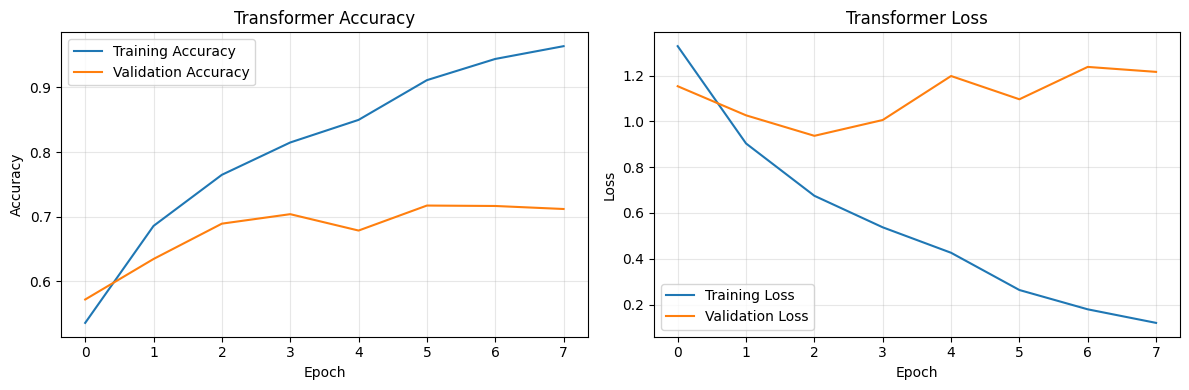

In [16]:
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Transformer Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True, alpha=0.3)

plt.subplot(1, 2, 2)
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Transformer Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig(os.path.join(RESULTS_DIR, "transformer_training_curves.png"),
            dpi=300, bbox_inches="tight")
plt.show()


12. Test Set Evaluation

Evaluates the trained model using accuracy, weighted precision, weighted recall, weighted F1-score, and a classification report.

In [17]:
from sklearn.metrics import classification_report

test_loss, test_accuracy = transformer_model.evaluate(
    X_test, y_test, verbose=0
)

y_prob = transformer_model.predict(X_test, verbose=0)
y_pred = np.argmax(y_prob, axis=1)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(
    y_test, y_pred, average="weighted", zero_division=0
)
recall = recall_score(
    y_test, y_pred, average="weighted", zero_division=0
)
f1 = f1_score(
    y_test, y_pred, average="weighted", zero_division=0
)

print("========== TRANSFORMER TEST RESULTS ==========")
print(f"Test Loss:  {test_loss:.4f}")
print(f"Accuracy:   {accuracy * 100:.2f}%")
print(f"Precision:  {precision * 100:.2f}%")
print(f"Recall:     {recall * 100:.2f}%")
print(f"F1-Score:   {f1 * 100:.2f}%")

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_)),
    target_names=label_encoder.classes_,
    zero_division=0
))


========== TRANSFORMER TEST RESULTS ==========
Test Loss:  1.2943
Accuracy:   61.73%
Precision:  63.61%
Recall:     61.73%
F1-Score:   62.01%

Classification Report:
              precision    recall  f1-score   support

       blues       0.61      0.47      0.53       150
   classical       0.83      0.99      0.90       150
     country       0.53      0.61      0.57       150
       disco       0.49      0.45      0.47       150
      hiphop       0.52      0.64      0.57       150
        jazz       0.86      0.64      0.73       150
       metal       0.89      0.66      0.76       150
         pop       0.73      0.65      0.69       150
      reggae       0.55      0.62      0.58       150
        rock       0.37      0.44      0.40       150

    accuracy                           0.62      1500
   macro avg       0.64      0.62      0.62      1500
weighted avg       0.64      0.62      0.62      1500



13. Confusion Matrix

Visualizes correct predictions and misclassifications across the ten music genres.

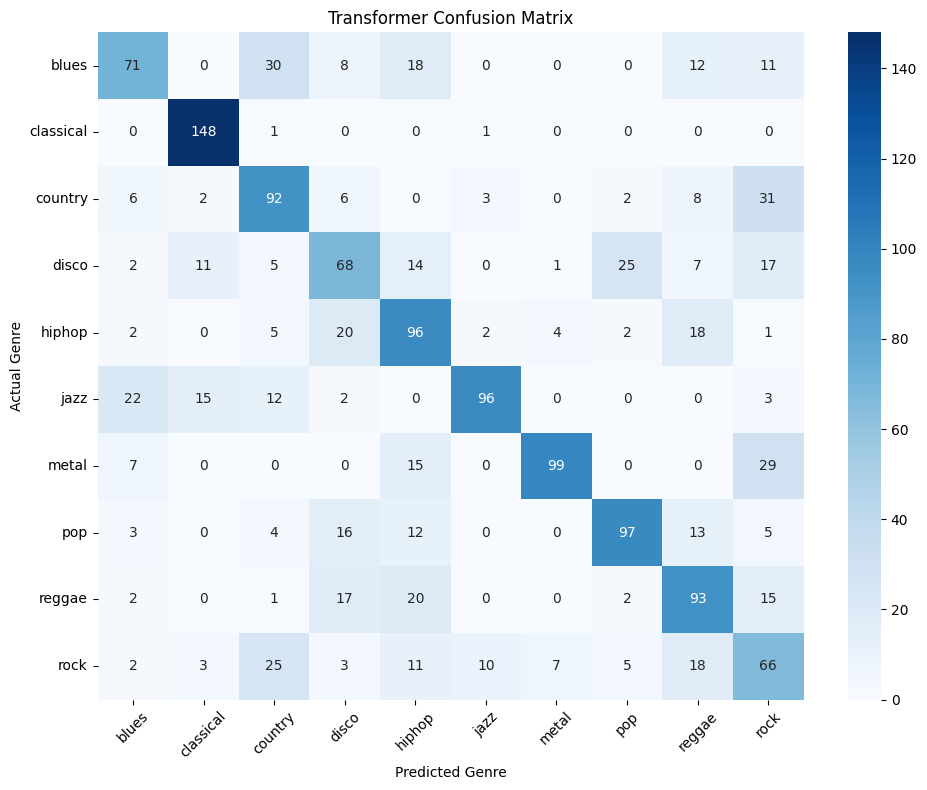

In [18]:
cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(label_encoder.classes_))
)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=label_encoder.classes_,
    yticklabels=label_encoder.classes_
)

plt.title("Transformer Confusion Matrix")
plt.xlabel("Predicted Genre")
plt.ylabel("Actual Genre")
plt.xticks(rotation=45)
plt.yticks(rotation=0)
plt.tight_layout()

plt.savefig(
    os.path.join(RESULTS_DIR, "transformer_confusion_matrix.png"),
    dpi=300,
    bbox_inches="tight"
)
plt.show()


14. Save Model and Results

Saves the trained Transformer, evaluation metrics, and results for future use and reporting.

In [19]:
transformer_model.save(
    os.path.join(RESULTS_DIR, "transformer_gtzan.keras")
)

metrics = {
    "Model": "Transformer",
    "Test Loss": float(test_loss),
    "Accuracy (%)": float(accuracy * 100),
    "Weighted Precision (%)": float(precision * 100),
    "Weighted Recall (%)": float(recall * 100),
    "Weighted F1-Score (%)": float(f1 * 100)
}

metrics_df = pd.DataFrame([metrics])
metrics_df.to_csv(
    os.path.join(RESULTS_DIR, "transformer_metrics.csv"),
    index=False
)

print("Saved model and metrics in:", RESULTS_DIR)
print(metrics_df.to_string(index=False))


Saved model and metrics in: results
      Model  Test Loss  Accuracy (%)  Weighted Precision (%)  Weighted Recall (%)  Weighted F1-Score (%)
Transformer   1.294303     61.733333               63.606513            61.733333              62.005478


## 15. Error Analysis

Based on the Transformer model's test confusion matrix and classification report:

#### 1. High-Performing Genres

- Classical: Achieved the highest recall (148 out of 150 segments, 98.7%) and an F1-score of 0.90, indicating highly reliable classification.
- Metal: Achieved the highest precision (0.89) and a recall of 66.0%, showing that metal predictions are generally reliable, although some segments are missed.
- Jazz: Recorded the second-highest precision (0.86) and an F1-score of 0.73, indicating that jazz predictions are accurate despite some misclassifications.
- Pop: Achieved an F1-score of 0.69, demonstrating moderate classification performance.

#### 2. Frequently Confused Genres

- Rock: Had the lowest F1-score (0.40) and precision (0.37), with only 66 out of 150 segments correctly classified (44.0% recall). It was frequently misclassified as Country (25 segments), Reggae (18 segments), and Hiphop (11 segments).
- Disco: Achieved a recall of 45.3%, with frequent confusion with Pop (25 segments), Hiphop (14 segments), and Classical (11 segments).
- Blues: Correctly classified 71 out of 150 segments (47.3% recall) and was often misclassified as Country (30 segments), Hiphop (18 segments), and Reggae (12 segments).
- Country: Achieved a recall of 61.3%, but was frequently confused with Rock (31 segments) and Reggae (8 segments).
- Hiphop and Reggae: Both showed moderate performance, with recalls of 64.0% and 62.0%, respectively. Hiphop was often confused with Disco (20 segments), while Reggae was frequently confused with Hiphop (20 segments) and Rock (15 segments).

#### 3. Overall Model Performance

The Transformer achieved 61.73% test accuracy, with weighted precision of 63.61%, weighted recall of 61.73%, and weighted F1-score of 62.01%. The results indicate strong performance on Classical music but weaker discrimination among genres with overlapping musical characteristics, particularly Rock, Disco, and Blues.